# 06 – Finding 3: does the pincode change the decision?
**Test:** take the applicants the model approves at a neutral pincode (560034, Bengaluru) and move
them to other pincodes, changing nothing else.
**Expected if the model is fair:** moving someone should not change their decision.

In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
from common import BLUE, finish_chart, load_data, sweep, what_if

df = load_data()
_, rejected = what_if(df, pincode=560034)
approved = df[~rejected]
print("Approved at pincode 560034:", len(approved))

Approved at pincode 560034: 254


## 1. Every pincode from 100000 to 999000 (steps of 1,000)

In [2]:
allpins = sweep(approved, "pincode", range(100000, 1000000, 1000), probe_file="06_pincode_sweep.csv")
by_prefix = allpins.groupby(allpins.pincode // 10000).reject_rate.max().rename("worst_reject_rate")
by_prefix[by_prefix > 0.02]   # every prefix not listed stays at or below 2%

pincode
10    0.024
11    0.024
12    0.024
13    0.024
40    0.035
41    0.587
42    0.185
Name: worst_reject_rate, dtype: float64

**What to notice:** only prefixes 40–42 matter, and **41** most of all. My first idea, from
notebook 01, was broad regional bias. That turns out to be **false**: once the applicants are held the
same, all other regions behave alike.

## 2. Close-up of 400000 – 430000

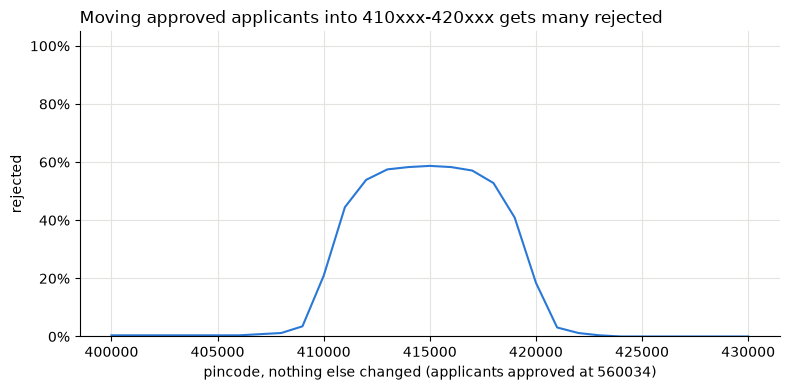

In [3]:
close = allpins[allpins.pincode.between(400000, 430000)]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(close.pincode, close.reject_rate, color=BLUE)
ax.set_xlabel("pincode, nothing else changed (applicants approved at 560034)")
ax.ticklabel_format(style="plain", axis="x")
finish_chart(ax, "Moving approved applicants into 410xxx-420xxx gets many rejected", "fig3_pincode.png")

The penalty rises and falls smoothly, because the model treats pincode as an ordinary number
rather than a place.

## 3. Who gets hit? Same people, fixed loan amount, 560034 vs 415000
Only about half of the people moved to 41xxxx were rejected. The ones who were all had larger loans,
so here the loan amount is fixed and only the pincode differs.

In [4]:
rows = []
for loan in [100000, 200000, 250000, 300000, 400000, 600000]:
    _, at_560 = what_if(approved, loan_amount=loan, pincode=560034)
    _, at_415 = what_if(approved, loan_amount=loan, pincode=415000)
    rows.append({"loan_amount": loan, "reject_at_560034": at_560.mean(), "reject_at_415000": at_415.mean()})
table = pd.DataFrame(rows).round(3)
table

,loan_amount,reject_at_560034,reject_at_415000
0,100000,0.004,0.004
1,200000,0.035,0.043
2,250000,0.075,0.114
3,300000,0.098,0.756
4,400000,0.150,1.000
5,600000,0.295,1.000


## 4. Were the old decisions already doing this?

In [5]:
df["label_rejected"] = df.decision == "reject"
_, df["model_rejected_elsewhere"] = what_if(df, pincode=560034)
df["region_41"] = df.pincode // 10000 == 41
df["loan_over_3L"] = df.loan_amount > 300000
table = (df.groupby(["region_41", "loan_over_3L"])
         .agg(applicants=("label_rejected", "size"), label_reject_rate=("label_rejected", "mean"),
              model_reject_rate_if_moved=("model_rejected_elsewhere", "mean"))
         .round(3).reset_index())
table

,region_41,loan_over_3L,applicants,label_reject_rate,model_reject_rate_if_moved
0,False,False,215,0.493,0.493
1,False,True,358,0.634,0.634
2,True,False,10,0.600,0.600
3,True,True,17,1.000,0.412


**Conclusion:** in pincodes around 410000–420000, loans above about ₹3 lakh are rejected. In the old
decisions, all 17 such applicants were rejected, while the model would reject only 41% of the same
people at another pincode. The model learned a hidden regional limit.